# Powerplant Data

#### Steps:
- Load the data
- Convert data into Tensor
- Create Tensor dataset and Data loader for Tensors
- Define ANN
- Actually Train the model (can also SAVE the model)
- Evaluate the model

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('powerplant_data.csv')

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


#### Values
- AT : Temperature
- V : Vaccum
- AP : Pressure
- RH : Humidity
- PE : Produced Energy

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [7]:
X = df.drop('PE', axis=1)
y = df['PE']

In [8]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [9]:
## Split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

In [10]:
df.shape

(9568, 5)

In [11]:
# apply standard scaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [16]:
## Convert Data into Tensors
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1) 
# y_train is a pandas series, so we use .values, .view func we pass row,column to convert the shape.

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1) 

In [17]:
type(y_train)

pandas.Series

In [18]:
# Create the Tensordataset and DataLoader

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [19]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

#### Deep Learning

In [32]:
## Building the ANN model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st Hidden Layer
            nn.Linear(X_train.shape[1],6), # input, output
            nn.ReLU(),

            # 2nd Hidden Layer
            nn.Linear(6,6),
            nn.ReLU(),

            # Output Layer
            nn.Linear(6,1),
        )

    def forward(self, x):
        return self.model(x)

In [33]:
# define loss func and Optimzer

import torch.optim as optim

model = ANN()

# loss, optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [35]:
# Train the ANN
training_losses = [] #  training step loss for every epoch
validation_losses = []


epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epoch
    

    for xb, yb in train_loader:
        # xb = features of one batch
        # yb = labels of one batch
        optimizer.zero_grad() # old gradients removed

        outputs = model(xb) # Forward prop...predicted output for this batch
        loss = criterion(outputs, yb) # compute loss for 1 batch
        loss.backward() # back prop.. compute gradients
        optimizer.step() # params update
    
        running_loss += loss.item() # loss is a tensor value so we convert it to float value

    epoch_train_loss = running_loss/len(train_loader)
    training_losses.append(epoch_train_loss)


    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no gradients compute (we dont compute gradients in validation)
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = criterion(outputs, yb)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss/len(test_loader)
    validation_losses.append(epoch_val_loss)

    print(f'Epoch {epoch+1}/{epochs} ===> train loss = {epoch_train_loss} & Val loss = {epoch_val_loss}')

Epoch 1/100 ===> train loss = 202690.44615885417 & Val loss = 196607.959375
Epoch 2/100 ===> train loss = 184181.61901041667 & Val loss = 168040.82786458332
Epoch 3/100 ===> train loss = 146029.1902669271 & Val loss = 122169.916015625
Epoch 4/100 ===> train loss = 97179.82862955729 & Val loss = 73534.22825520833
Epoch 5/100 ===> train loss = 54224.90134277344 & Val loss = 38528.81318359375
Epoch 6/100 ===> train loss = 28871.699129231773 & Val loss = 21945.801725260415
Epoch 7/100 ===> train loss = 18569.821634928387 & Val loss = 16000.083170572916
Epoch 8/100 ===> train loss = 14645.354833984375 & Val loss = 13172.135172526041
Epoch 9/100 ===> train loss = 12212.635516357423 & Val loss = 10965.45909016927
Epoch 10/100 ===> train loss = 10095.503116861979 & Val loss = 8951.900927734376
Epoch 11/100 ===> train loss = 8181.195127360026 & Val loss = 7130.19375
Epoch 12/100 ===> train loss = 6424.724626668294 & Val loss = 5523.0389689127605
Epoch 13/100 ===> train loss = 4896.990783691406 

<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

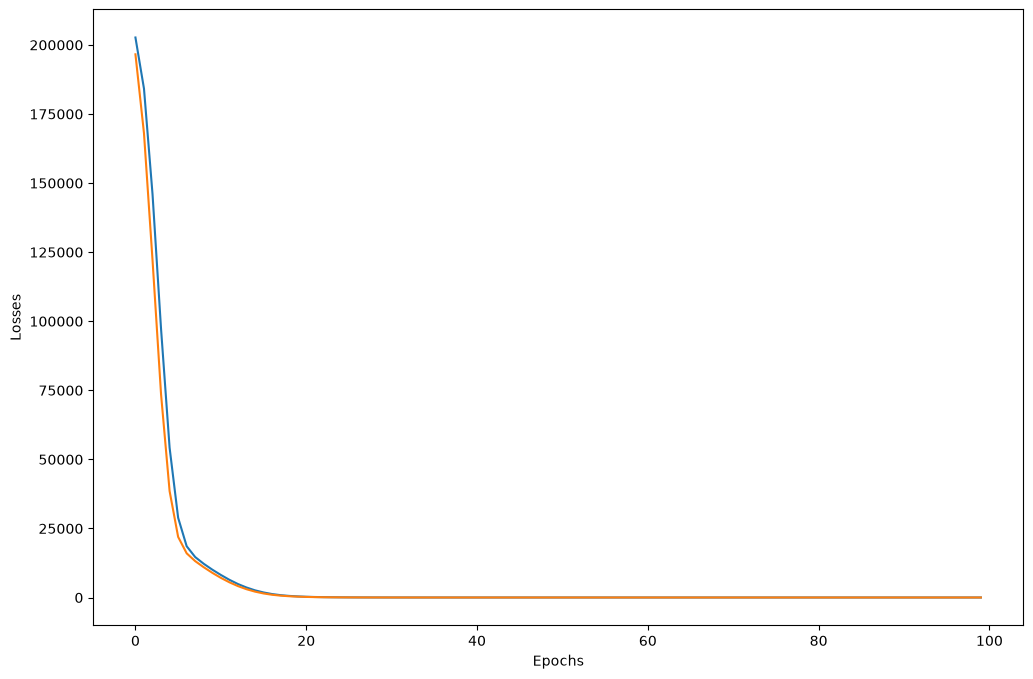

In [37]:
# plot

import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    'Training Loss' : training_losses,
    'Validation Loss' : validation_losses
})

plt.figure(figsize=(12,8))
plt.plot(loss_df['Training Loss'], label = 'Training Loss')
plt.plot(loss_df['Validation Loss'], label = 'Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Losses')

plt.legend